# Overlapping Mitigation

### <i> Using ClusterCentroids

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("../houses.csv")

# drop unneeded variables
df.drop(["id", "date", "lat", "long", 'zipcode'], axis=1, inplace=True)
df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,1340,5650
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,1690,7639
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,2720,8062
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,1360,5000
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000.0,3,2.50,1530,1131,3.0,0,0,3,8,1530,0,2009,0,1530,1509
21609,400000.0,4,2.50,2310,5813,2.0,0,0,3,8,2310,0,2014,0,1830,7200
21610,402101.0,2,0.75,1020,1350,2.0,0,0,3,7,1020,0,2009,0,1020,2007
21611,400000.0,3,2.50,1600,2388,2.0,0,0,3,8,1600,0,2004,0,1410,1287


In [2]:
# let's filter some extreme outliers on the high end
df.query("price <= price.quantile(0.99)", inplace=True)

<Axes: xlabel='target_binned', ylabel='Count'>

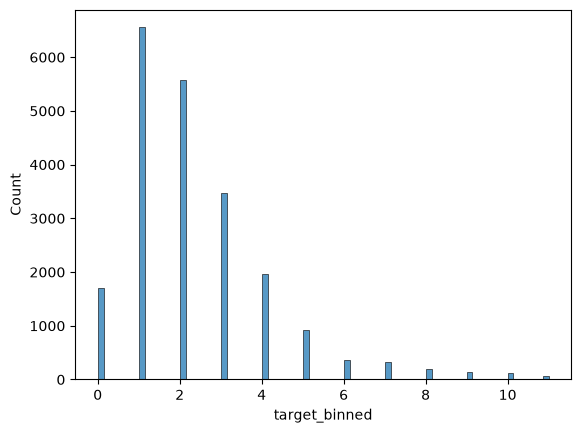

In [3]:
# Create 12 bins of price. 
target = "price"
df['target_binned'] = pd.cut(df[target], bins=12, labels=False)

# That looks like so.
sns.histplot(df, x="target_binned")

---

### The problem

In [4]:
# The current problem is that our dataset has a significant amount of overlap that could 
# affect our ML models. Take a look.
# sns.pairplot(df, hue="Rating")

In [5]:
df.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15,target_binned
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,1340,5650,0
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,1690,7639,2
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,2720,8062,0
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,1360,5000,3
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,1800,7503,2


<Axes: xlabel='grade', ylabel='sqft_living'>

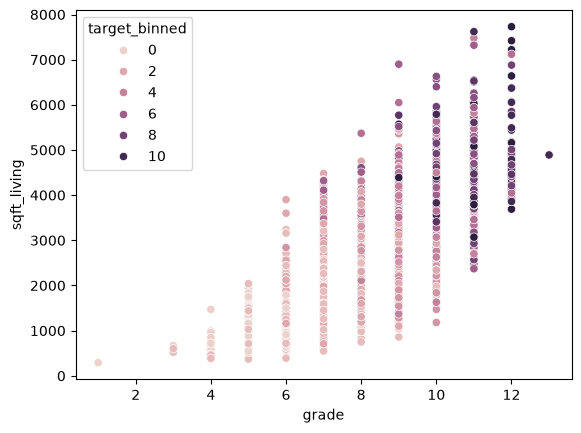

In [6]:
# Now let's take a particularly nasty overlap. Here.
sns.scatterplot(df, x="grade", y="sqft_living", hue="target_binned")

# In real life, does this overlap seem feasable? Probably.
# There's always some overlap (especially in health diagnosis data).

# But say this didn't reflect reality and there's some reason to 
# fix the overlap (to which there are many)...

--- 

### ClusterCentroids

In [7]:
from imblearn.under_sampling import ClusterCentroids

# X y split to prevent data leakage
X = df.drop(columns="target_binned", axis=1)
y = df["target_binned"]

strategy = {
    0 : 1704,
    1 : 4553,
    2 : 4571,
    3 : 3476,
    4 : 1957,
    5 : 928,
    6 : 368,
    7 : 328,
    8 : 190,
    9 : 132,
    10 : 116,
    11 : 73
}


cc = ClusterCentroids(
    sampling_strategy=strategy,
    random_state=321
)

X_resampled, y_resampled = cc.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_resampled = X_resampled.copy()

# Add y back into the X rows
df_resampled["target_binned"] = y_resampled
df_resampled

c:\Users\tuomas.valtanen\dataeng_advda2026_lectures\DataEngineering_AdvDA_2026\.venv\Lib\site-packages\sklearn\base.py:1403: ConvergenceWarning: Number of distinct clusters (3473) found smaller than n_clusters (3476). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15,target_binned
0,157000.0,3,1.00,1080,6250,1.0,0,0,2,5,1080,0,1950,0,1070,6250,0
1,211000.0,4,1.00,2100,9200,1.0,0,0,3,7,1050,1050,1959,0,1540,10033,0
2,190000.0,2,1.00,710,1164794,1.0,0,0,2,5,710,0,1915,0,1680,16730,0
3,150000.0,2,1.00,720,212137,1.0,0,0,3,5,720,0,1982,0,2010,109642,0
4,110000.0,3,1.00,1250,53143,1.0,0,0,5,6,1250,0,1945,0,1820,217800,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18391,1950000.0,3,2.50,2510,12779,1.5,0,4,3,10,2510,0,1968,0,2810,12225,11
18392,1875000.0,5,3.25,4110,7920,2.0,0,3,3,9,3150,960,1921,0,3890,7800,11
18393,1850000.0,4,3.25,3480,6000,3.0,0,0,3,8,3480,0,2014,0,2200,4080,11
18394,1900000.0,6,4.00,3020,13237,2.0,1,4,3,8,2840,180,1942,1983,3680,12620,11


Text(0.5, 1.0, 'Original Data')

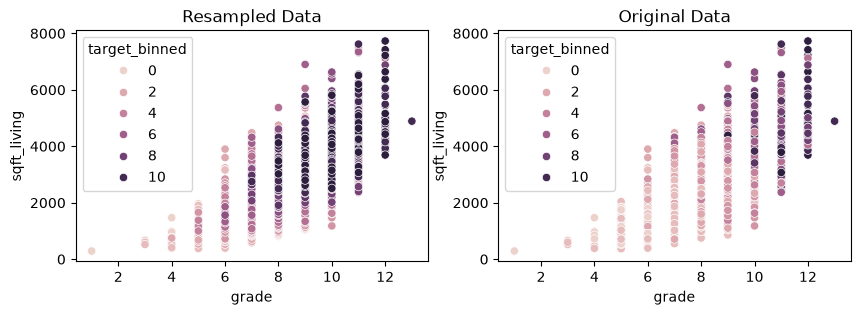

In [8]:
# Let's look at it again. How did it perform?
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.scatterplot(df, x="grade", y="sqft_living", hue="target_binned", ax=axes[1])    
sns.scatterplot(df_resampled, x="grade", y="sqft_living", hue="target_binned", ax=axes[0])
axes[0].set_title("Resampled Data")
axes[1].set_title("Original Data")
# Not bad too, but still a little underwhelming.

In [9]:
# But let's do a sanity check. How many rows did it get rid of?
print(df.shape)
print(df_resampled.shape)

(21396, 17)
(18396, 17)


In [10]:
df['grade'].value_counts().sort_index()

grade
1        1
3        3
4       29
5      242
6     2038
7     8980
8     6062
9     2594
10    1068
11     324
12      54
13       1
Name: count, dtype: int64

In [11]:
df_resampled['grade'].value_counts().sort_index()

grade
1        1
3        3
4       29
5      224
6     1855
7     7300
8     5048
9     2492
10    1065
11     324
12      54
13       1
Name: count, dtype: int64